In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [21]:
df = pd.read_parquet("cleaned_data/merged.parquet")

print("Shape:", df.shape)
df.head()

Shape: (366313, 38)


,interval_start_utc,interval_end_utc,publish_time_utc,north_derated_outages_mw,north_forced_outages_mw,north_planned_outages_mw,north_unplanned_outages_mw,central_derated_outages_mw,central_forced_outages_mw,central_planned_outages_mw,...,south_wind,miso_wind,north_solar,central_solar,south_solar,miso_solar,lmp_dam,energy_dam,congestion_dam,loss_dam
0,2023-03-25 01:55:00+00:00,2023-03-25 02:00:00+00:00,2023-03-23 05:00:00+00:00,399.0,155.0,2895.0,285.0,1999.0,3006.0,18439.0,...,0.0,9920.8,3.9,1.0,1.2,6.1,26.92,26.09,1.66,-0.83
1,2023-03-25 02:00:00+00:00,2023-03-25 02:05:00+00:00,2023-03-23 05:00:00+00:00,399.0,155.0,2895.0,285.0,1999.0,3006.0,18439.0,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85
2,2023-03-25 02:05:00+00:00,2023-03-25 02:10:00+00:00,2023-03-23 05:00:00+00:00,399.0,155.0,2895.0,285.0,1999.0,3006.0,18439.0,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85
3,2023-03-25 02:10:00+00:00,2023-03-25 02:15:00+00:00,2023-03-23 05:00:00+00:00,399.0,155.0,2895.0,285.0,1999.0,3006.0,18439.0,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85
4,2023-03-25 02:15:00+00:00,2023-03-25 02:20:00+00:00,2023-03-23 05:00:00+00:00,399.0,155.0,2895.0,285.0,1999.0,3006.0,18439.0,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85


In [22]:
cols = [
    "interval_start_utc",
    "interval_end_utc",
    "load_forecast",
    "lmp_rtm",
    "lmp_dam",
    "miso_wind",
    "miso_solar",
    "miso_derated_outages_mw",
    "miso_forced_outages_mw",
    "miso_planned_outages_mw",
    "miso_unplanned_outages_mw"
]

work_df = df[cols].copy()

work_df["interval_start_utc"] = pd.to_datetime(
    work_df["interval_start_utc"], utc=True
)

work_df["interval_end_utc"] = pd.to_datetime(
    work_df["interval_end_utc"], utc=True
)

work_df = work_df.sort_values("interval_start_utc").reset_index(drop=True)

print("Shape:", work_df.shape)
work_df.head()

Shape: (366313, 11)


,interval_start_utc,interval_end_utc,load_forecast,lmp_rtm,lmp_dam,miso_wind,miso_solar,miso_derated_outages_mw,miso_forced_outages_mw,miso_planned_outages_mw,miso_unplanned_outages_mw
0,2023-03-25 01:55:00+00:00,2023-03-25 02:00:00+00:00,71099,28.03,26.92,9920.8,6.1,3158.0,3587.0,33776.0,3491.0
1,2023-03-25 02:00:00+00:00,2023-03-25 02:05:00+00:00,70934,25.08,23.70,10810.9,0.0,3158.0,3587.0,33776.0,3491.0
2,2023-03-25 02:05:00+00:00,2023-03-25 02:10:00+00:00,70768,27.07,23.70,10810.9,0.0,3158.0,3587.0,33776.0,3491.0
3,2023-03-25 02:10:00+00:00,2023-03-25 02:15:00+00:00,70602,26.10,23.70,10810.9,0.0,3158.0,3587.0,33776.0,3491.0
4,2023-03-25 02:15:00+00:00,2023-03-25 02:20:00+00:00,70436,24.82,23.70,10810.9,0.0,3158.0,3587.0,33776.0,3491.0


In [23]:
print(work_df.isna().sum())
numeric_cols = work_df.select_dtypes(include="number").columns

work_df[numeric_cols] = work_df[numeric_cols].interpolate(
    method="linear"
)
work_df[numeric_cols] = work_df[numeric_cols].ffill().bfill()
print(work_df.isna().sum())

interval_start_utc              0
interval_end_utc                0
load_forecast                   0
lmp_rtm                      5602
lmp_dam                         0
miso_wind                       0
miso_solar                      0
miso_derated_outages_mw      5185
miso_forced_outages_mw       5185
miso_planned_outages_mw      5185
miso_unplanned_outages_mw    6049
dtype: int64
interval_start_utc           0
interval_end_utc             0
load_forecast                0
lmp_rtm                      0
lmp_dam                      0
miso_wind                    0
miso_solar                   0
miso_derated_outages_mw      0
miso_forced_outages_mw       0
miso_planned_outages_mw      0
miso_unplanned_outages_mw    0
dtype: int64


In [24]:
means = work_df[numeric_cols].mean()
stds = work_df[numeric_cols].std()

stats = pd.DataFrame({
    "Mean": means,
    "Standard Deviation": stds
})

stats

,Mean,Standard Deviation
load_forecast,77105.158739,12476.158464
lmp_rtm,34.356729,83.366531
lmp_dam,35.294881,33.367681
miso_wind,11368.805036,6284.692533
miso_solar,2597.467023,4061.915163
miso_derated_outages_mw,7601.346450,2082.959716
miso_forced_outages_mw,7461.303058,2528.279565
miso_planned_outages_mw,19369.260747,10961.025918
miso_unplanned_outages_mw,8156.658199,2697.342308


In [32]:
from pathlib import Path

# Create folder for artificial data
output_dir = Path("artificial_data")
output_dir.mkdir(exist_ok=True)

# Number of artificial datasets
n_datasets = 3

# Random number generator
rng = np.random.default_rng(42)

In [33]:
# Columns that cannot have negative values
nonnegative_cols = [
    "load_forecast",
    "miso_wind",
    "miso_solar",
    "miso_derated_outages_mw",
    "miso_forced_outages_mw",
    "miso_planned_outages_mw",
    "miso_unplanned_outages_mw"
]

In [34]:
artificial_datasets = []

for i in range(n_datasets):

    # Keep original timestamps
    artificial_df = work_df[
        ["interval_start_utc", "interval_end_utc"]
    ].copy()

    # Generate artificial values
    for col in numeric_cols:
        artificial_df[col] = rng.normal(
            loc=means[col],
            scale=stds[col],
            size=len(work_df)
        )

    # Prevent negative values where needed
    for col in nonnegative_cols:
       artificial_df[col] = artificial_df[col].clip(lower=0)

    # Store artificial dataset
    artificial_datasets.append(artificial_df)

In [35]:
print("Number of datasets:", len(artificial_datasets))

for i, data in enumerate(artificial_datasets, start=1):
    print(f"Dataset {i}: {data.shape}")

Number of datasets: 3
Dataset 1: (366313, 11)
Dataset 2: (366313, 11)
Dataset 3: (366313, 11)


In [ ]:
artificial_df = artificial_datasets[0]

comparison = pd.DataFrame({
    "Real Mean": work_df[numeric_cols].mean(),
    "Artificial Mean": artificial_df[numeric_cols].mean(),
    "Real SD": work_df[numeric_cols].std(),
    "Artificial SD": artificial_df[numeric_cols].std()
})

comparison

,Real Mean,Artificial Mean,Real SD,Artificial SD
load_forecast,77105.158739,77105.762407,12476.158464,12482.152039
lmp_rtm,34.356729,34.197901,83.366531,83.399521
lmp_dam,35.294881,35.393761,33.367681,33.364611
miso_wind,11368.805036,11463.131991,6284.692533,6089.002572
miso_solar,2597.467023,3245.121418,4061.915163,3182.342227
miso_derated_outages_mw,7601.346450,7601.888250,2082.959716,2081.695389
miso_forced_outages_mw,7461.303058,7462.539458,2528.279565,2522.883551
miso_planned_outages_mw,19369.260747,19552.965761,10961.025918,10582.170874
miso_unplanned_outages_mw,8156.658199,8162.112336,2697.342308,2697.221388


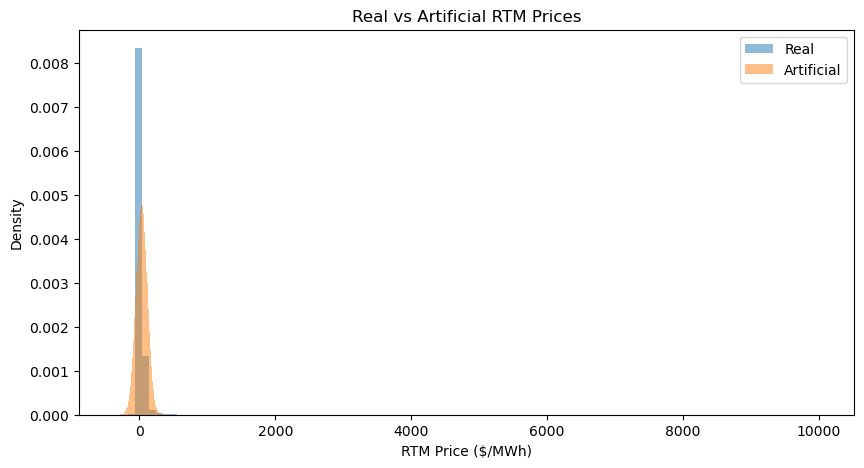

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(
    work_df["lmp_rtm"],
    bins=100,
    alpha=0.5,
    density=True,
    label="Real"
)

plt.hist(
    artificial_df["lmp_rtm"],
    bins=100,
    alpha=0.5,
    density=True,
    label="Artificial"
)

plt.xlabel("RTM Price ($/MWh)")
plt.ylabel("Density")
plt.title("Real vs Artificial RTM Prices")
plt.legend()
plt.show()

In [ ]:
for i, data in enumerate(artificial_datasets, start=1):

    filename = f"artificail_miso_{i}.parquet"

    data.to_parquet(
        output_dir / filename,
        index=False
    )

    print(f"Saved {filename}")

Saved synthetic_miso_1.parquet
Saved synthetic_miso_2.parquet
Saved synthetic_miso_3.parquet
